# Data Processing

## Import packages
Dependency Specification: pandas==3.0.5, duckdb==1.5.6

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

from utils import *

## Load Data

Load data and select features with an SQL query through the duckdb.

In [2]:
year_selected = "2026" # temporarily hardcoded df year

In [3]:
con = duckdb.connect("lol_predictors.duckdb")

df = con.execute(f"SELECT * FROM df_{year_selected}").df()

con.close()

## Feature Exclusions
Features that have zero correlations with the target feature `result` or that correlate with each other should be dropped to avoid multicollinearity.

In [4]:
# Compute correlation matrix and define the correlations of the target feature
corr_mtx = df.corr(numeric_only=True)
target_corr = corr_mtx['result'].abs()

# Find and drop features where correlation around 0.00
zero_corr_cols = target_corr[target_corr < 0.01].index.tolist()
df = df.drop(columns=zero_corr_cols, errors='ignore')

print("Dropped zero-correlation features:", zero_corr_cols)

Dropped zero-correlation features: ['ckpm']


After remove the features with zero correlations with the target feature `result`, we will have to manually remove the features that have high correlation with each other to apply domain knowledge on which of the two correlated features should retain.

In [5]:
# Adjust list based on the features considered
cols_to_drop = [
                'wardskilled',
                # All deaths stats are removed because they mirror their opps kills and assists
                'deathsat10', 'deathsat15', 'deathsat20', 'deathsat25',
                'opp_deathsat10', 'opp_deathsat15', 'opp_deathsat20', 'opp_deathsat25',
                # `golddiffat15` and `xpdiffat15` surprisingly has a 0.85 corr value. 'golddiffat15' is removed because it has high collinearity with other features
                'golddiffat15',
                # Ingame stats from other timestamps does correlate past 0.80 with each other except for the 20th minute mark
                'golddiffat20', 'xpdiffat20',
                # `golddiffat25` and `xpdiffat25` has a 0.89 corr value. `xpdiffat25` is removed because gold has more impact in the late game
                'xpdiffat25'
                ]

df = df.drop(columns=cols_to_drop, errors='ignore')

Assists are not yet removed even though they have high collinearity with kills since they will be later used to calculate a support player's strength.

Also, while opponent stats also mirror with a team's stats, they will be retained to calculate "diff" features later.

## Data Imputation

Based on the EDA of `df_2026`, the missing values of the `split` feature are scattered. Since the values are chronological, we can use forward fill.

In [6]:
df['split'] = df['split'].ffill()

The features with missing values of <5% will be trimmed.

In [7]:
# Find all columns where missingness is less than 10% (and greater than 0%)
cols_to_clean = [col for col in df.columns if 0 < df[col].isnull().mean() < 0.1]

print("Columns being cleaned for missing rows:", cols_to_clean)

# Drop rows that have NaN values in any of those specific columns
df = df.dropna(subset=cols_to_clean).reset_index(drop=True)

Columns being cleaned for missing rows: ['teamid', 'doublekills', 'triplekills', 'quadrakills', 'pentakills', 'killsat10', 'assistsat10', 'opp_killsat10', 'killsat15', 'assistsat15', 'opp_killsat15', 'killsat20', 'assistsat20', 'opp_killsat20', 'killsat25', 'assistsat25', 'opp_killsat25', 'golddiffat10', 'xpdiffat10', 'xpdiffat15', 'golddiffat25']


## Outlier Treatment

The problem with treating the outliers of the current dataset is that each champion in each position have different playstyles. For example, a support pyke will naturally have more kills than a support soraka. That's why the outlier treatment will be moved after the features are engineered and only team-specific features are left.

In [8]:
# Limit numerical features for outlier trimming
# count_feats = ['doublekills', 'triplekills', 'quadrakills', 'pentakills']
# ignore_outliers =  [col for col in df.select_dtypes(include="number") if df[col].nunique() < 3 or col in count_feats]
# num_cols = df.select_dtypes(include=["number"]).columns.drop(ignore_outliers).tolist()
# print(num_cols)

# trimmed_groups = []
# for position, group in df.groupby("position"):
#     group_filtered = group.copy()

#     # Chain the filtering so each column strips its outliers
#     for col in num_cols:
#         is_outlier = detect_outliers(group_filtered, col)
#         group_filtered = group_filtered[~is_outlier]
#     trimmed_groups.append(group)

# df = pd.concat(trimmed_groups).reset_index(drop=True)

In [9]:
# # Check outliers per position
# for position, group in df.groupby("position"):
#     print("Group by the position:", position)
#     count_outliers(group, ignore_outliers)
#     print('\n')

This concludes the data cleaning of `df_2026`, which is the Lol Esports data on 2026 based on Oracle's Elixir. From the EDA, there are no categories among the categorical features that needs fixing. 

## Post-Processing Data Audit

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 103632 entries, 0 to 103631
Data columns (total 53 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   gameid            103632 non-null  str    
 1   league            103632 non-null  str    
 2   split             103632 non-null  str    
 3   date              103632 non-null  str    
 4   side              103632 non-null  str    
 5   position          103632 non-null  str    
 6   playername        86360 non-null   str    
 7   teamname          103632 non-null  str    
 8   teamid            103632 non-null  str    
 9   doublekills       103632 non-null  float64
 10  triplekills       103632 non-null  float64
 11  quadrakills       103632 non-null  float64
 12  pentakills        103632 non-null  float64
 13  firstbloodkill    86360 non-null   float64
 14  firstbloodassist  86360 non-null   float64
 15  firstbloodvictim  86360 non-null   float64
 16  visionscore       103632 non-nu

In [11]:
df.shape

(103632, 53)

In [12]:
display(df.describe())

,doublekills,triplekills,quadrakills,pentakills,firstbloodkill,firstbloodassist,firstbloodvictim,visionscore,result,team kpm,...,killsat20,assistsat20,opp_killsat20,killsat25,assistsat25,opp_killsat25,golddiffat10,xpdiffat10,xpdiffat15,golddiffat25
count,103632.00,103632.00,103632.00,103632.00,86360.00,86360.00,86360.00,103632.00,103632.00,103632.00,...,103632.00,103632.00,103632.00,103632.00,103632.00,103632.00,103632.00,103632.00,103632.00,103632.00
mean,0.58,0.10,0.02,0.00,0.10,0.13,0.10,97.61,0.50,0.53,...,2.52,4.44,2.51,3.63,7.14,3.62,3.20,2.23,4.90,15.10
std,1.05,0.35,0.13,0.06,0.30,0.33,0.30,99.89,0.50,0.26,...,3.24,5.64,3.22,4.55,8.76,4.52,756.06,598.72,1200.15,3300.52
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,4.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,-5581.00,-4370.00,-9590.00,-22049.00
25%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,35.00,0.00,0.32,...,0.00,1.00,0.00,1.00,2.00,1.00,-360.00,-318.00,-580.00,-1350.00
50%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,51.00,1.00,0.50,...,1.00,3.00,1.00,2.00,4.00,2.00,2.00,0.00,3.00,9.00
75%,1.00,0.00,0.00,0.00,0.00,0.00,0.00,124.00,1.00,0.69,...,3.00,5.00,3.00,5.00,8.00,5.00,365.00,321.00,588.00,1371.00
max,18.00,4.00,2.00,2.00,1.00,1.00,1.00,749.00,1.00,2.09,...,39.00,54.00,31.00,52.00,88.00,44.00,5581.00,4370.00,9590.00,22049.00


<Figure size 1400x800 with 0 Axes>

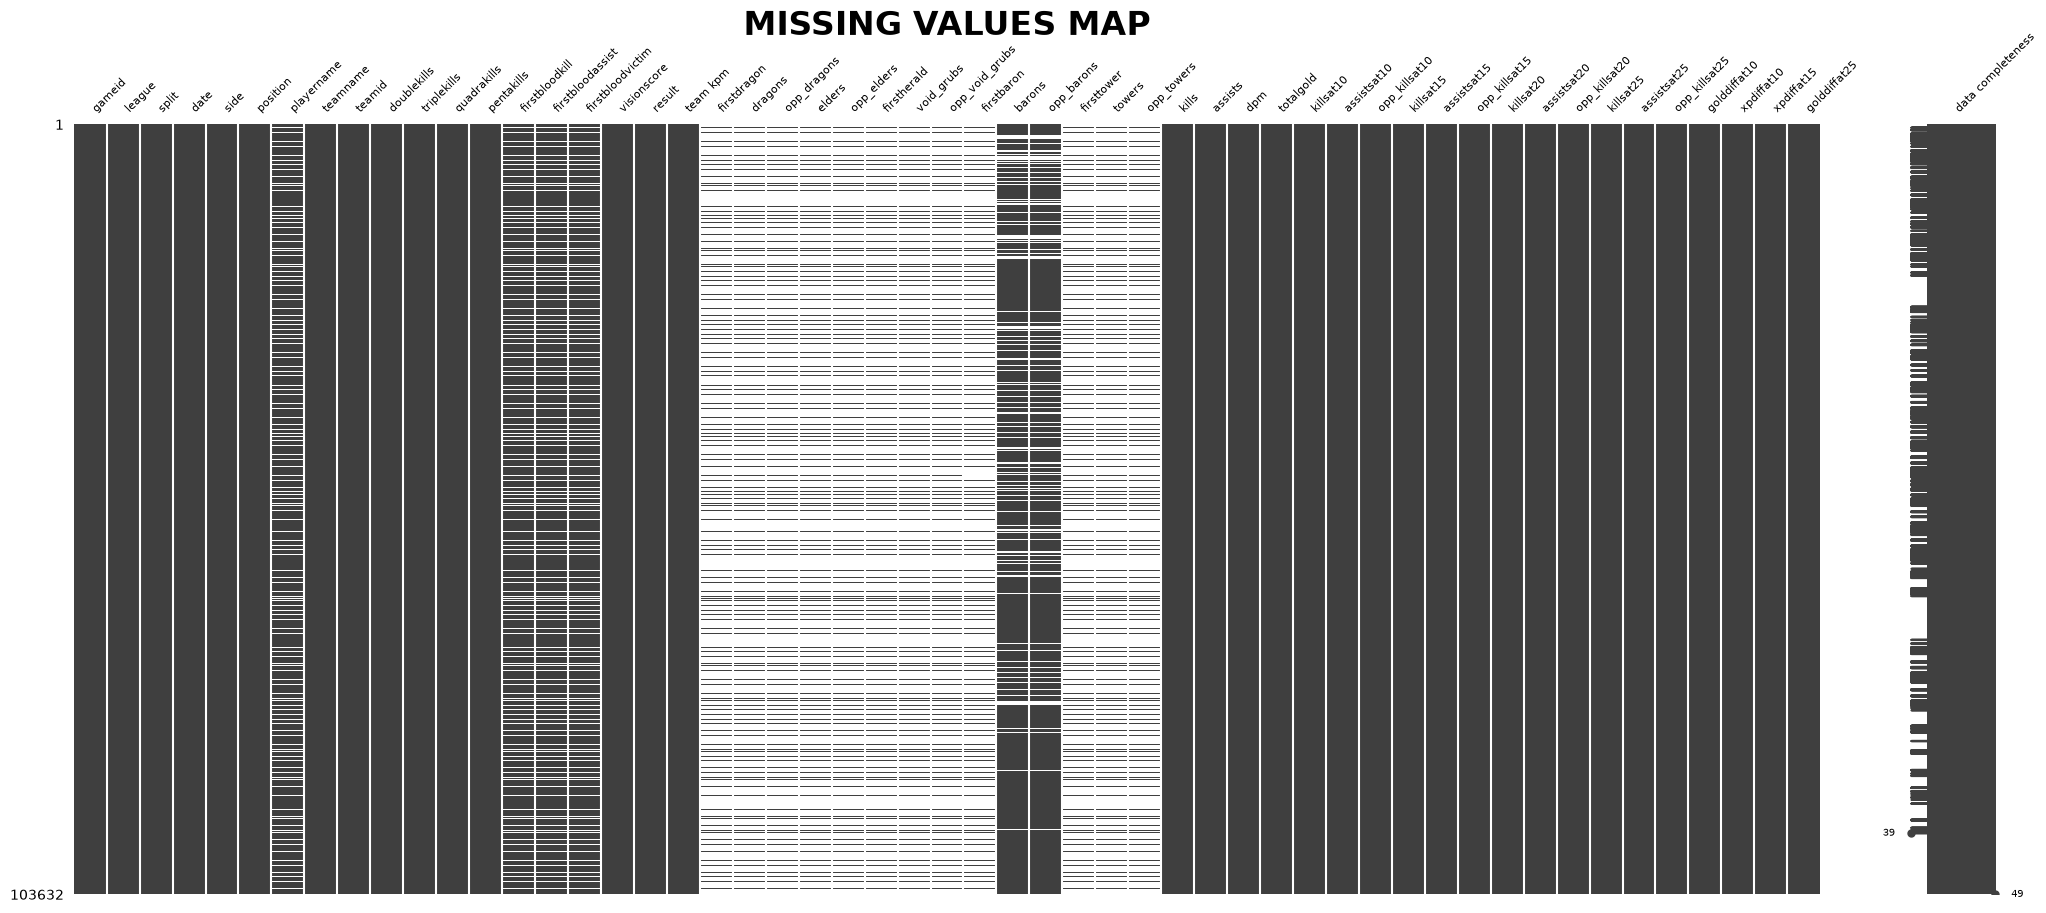


------------- MISSING VALUES REPORT --------------
                  Count   (%)
firstbaron        86472 83.44
dragons           86360 83.33
opp_towers        86360 83.33
towers            86360 83.33
elders            86360 83.33
firstdragon       86360 83.33
opp_elders        86360 83.33
firstherald       86360 83.33
void_grubs        86360 83.33
opp_dragons       86360 83.33
opp_void_grubs    86360 83.33
firsttower        86360 83.33
firstbloodkill    17272 16.67
playername        17272 16.67
firstbloodvictim  17272 16.67
firstbloodassist  17272 16.67
barons            13580 13.10
opp_barons        13580 13.10


In [13]:
null_map(df)

The data may not look clean, but features with ~83.33% missingness are team-specific while features with ~16.67% missingness are player-specific. Player-specific features will be consolidated later, leaving team-specific features only.

In [14]:
# Limit numerical columns for description and visualization
nunique_below100 = [col for col in df.select_dtypes(include="number") if df[col].nunique() < 100]
nunique_below3 =  [col for col in df.select_dtypes(include="number") if df[col].nunique() < 3 and col != 'result']
print(nunique_below100)
print(nunique_below3)

# Limit categorical columns for description and visualization
catcols_to_drop = [col for col in df.select_dtypes(include="str") if df[col].nunique() > 50]
print(catcols_to_drop)

['doublekills', 'triplekills', 'quadrakills', 'pentakills', 'firstbloodkill', 'firstbloodassist', 'firstbloodvictim', 'result', 'firstdragon', 'dragons', 'opp_dragons', 'elders', 'opp_elders', 'firstherald', 'void_grubs', 'opp_void_grubs', 'firstbaron', 'barons', 'opp_barons', 'firsttower', 'towers', 'opp_towers', 'kills', 'killsat10', 'assistsat10', 'opp_killsat10', 'killsat15', 'assistsat15', 'opp_killsat15', 'killsat20', 'assistsat20', 'opp_killsat20', 'killsat25', 'assistsat25', 'opp_killsat25']
['firstbloodkill', 'firstbloodassist', 'firstbloodvictim', 'firstdragon', 'firstherald', 'firstbaron', 'firsttower']
['gameid', 'date', 'playername', 'teamname', 'teamid']


*Note that the IQR bounds are dynamically recalculated on each call. These remaining outliers are relative to the newly trimmed distribution. Since the new percentage of outliers is < 1%, it is negligible and safe to retain.*

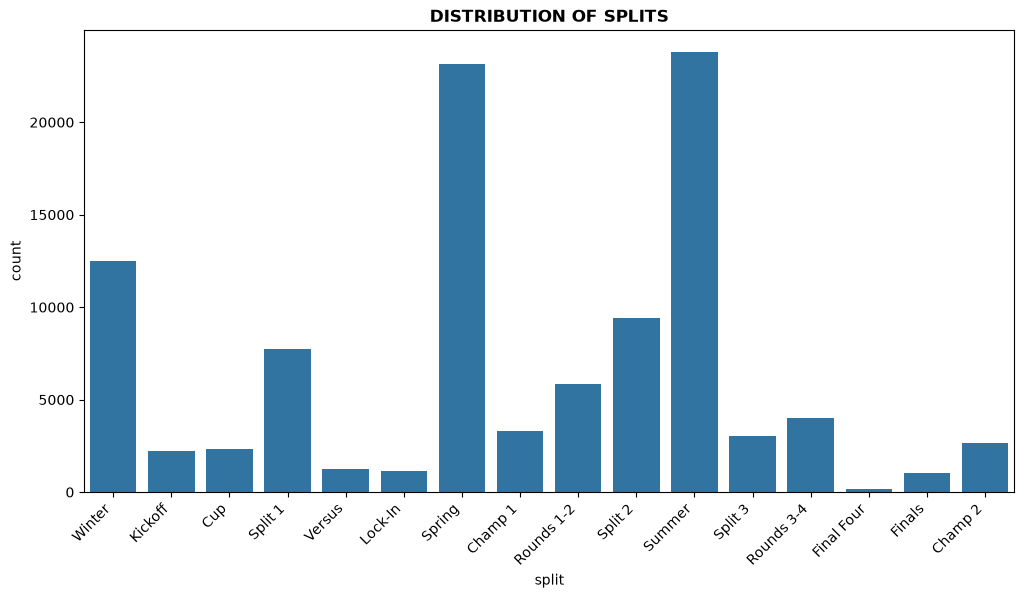

In [15]:
# Visualization of the Splits Distribution
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='split')
plt.title('DISTRIBUTION OF SPLITS', fontsize=12, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.show()

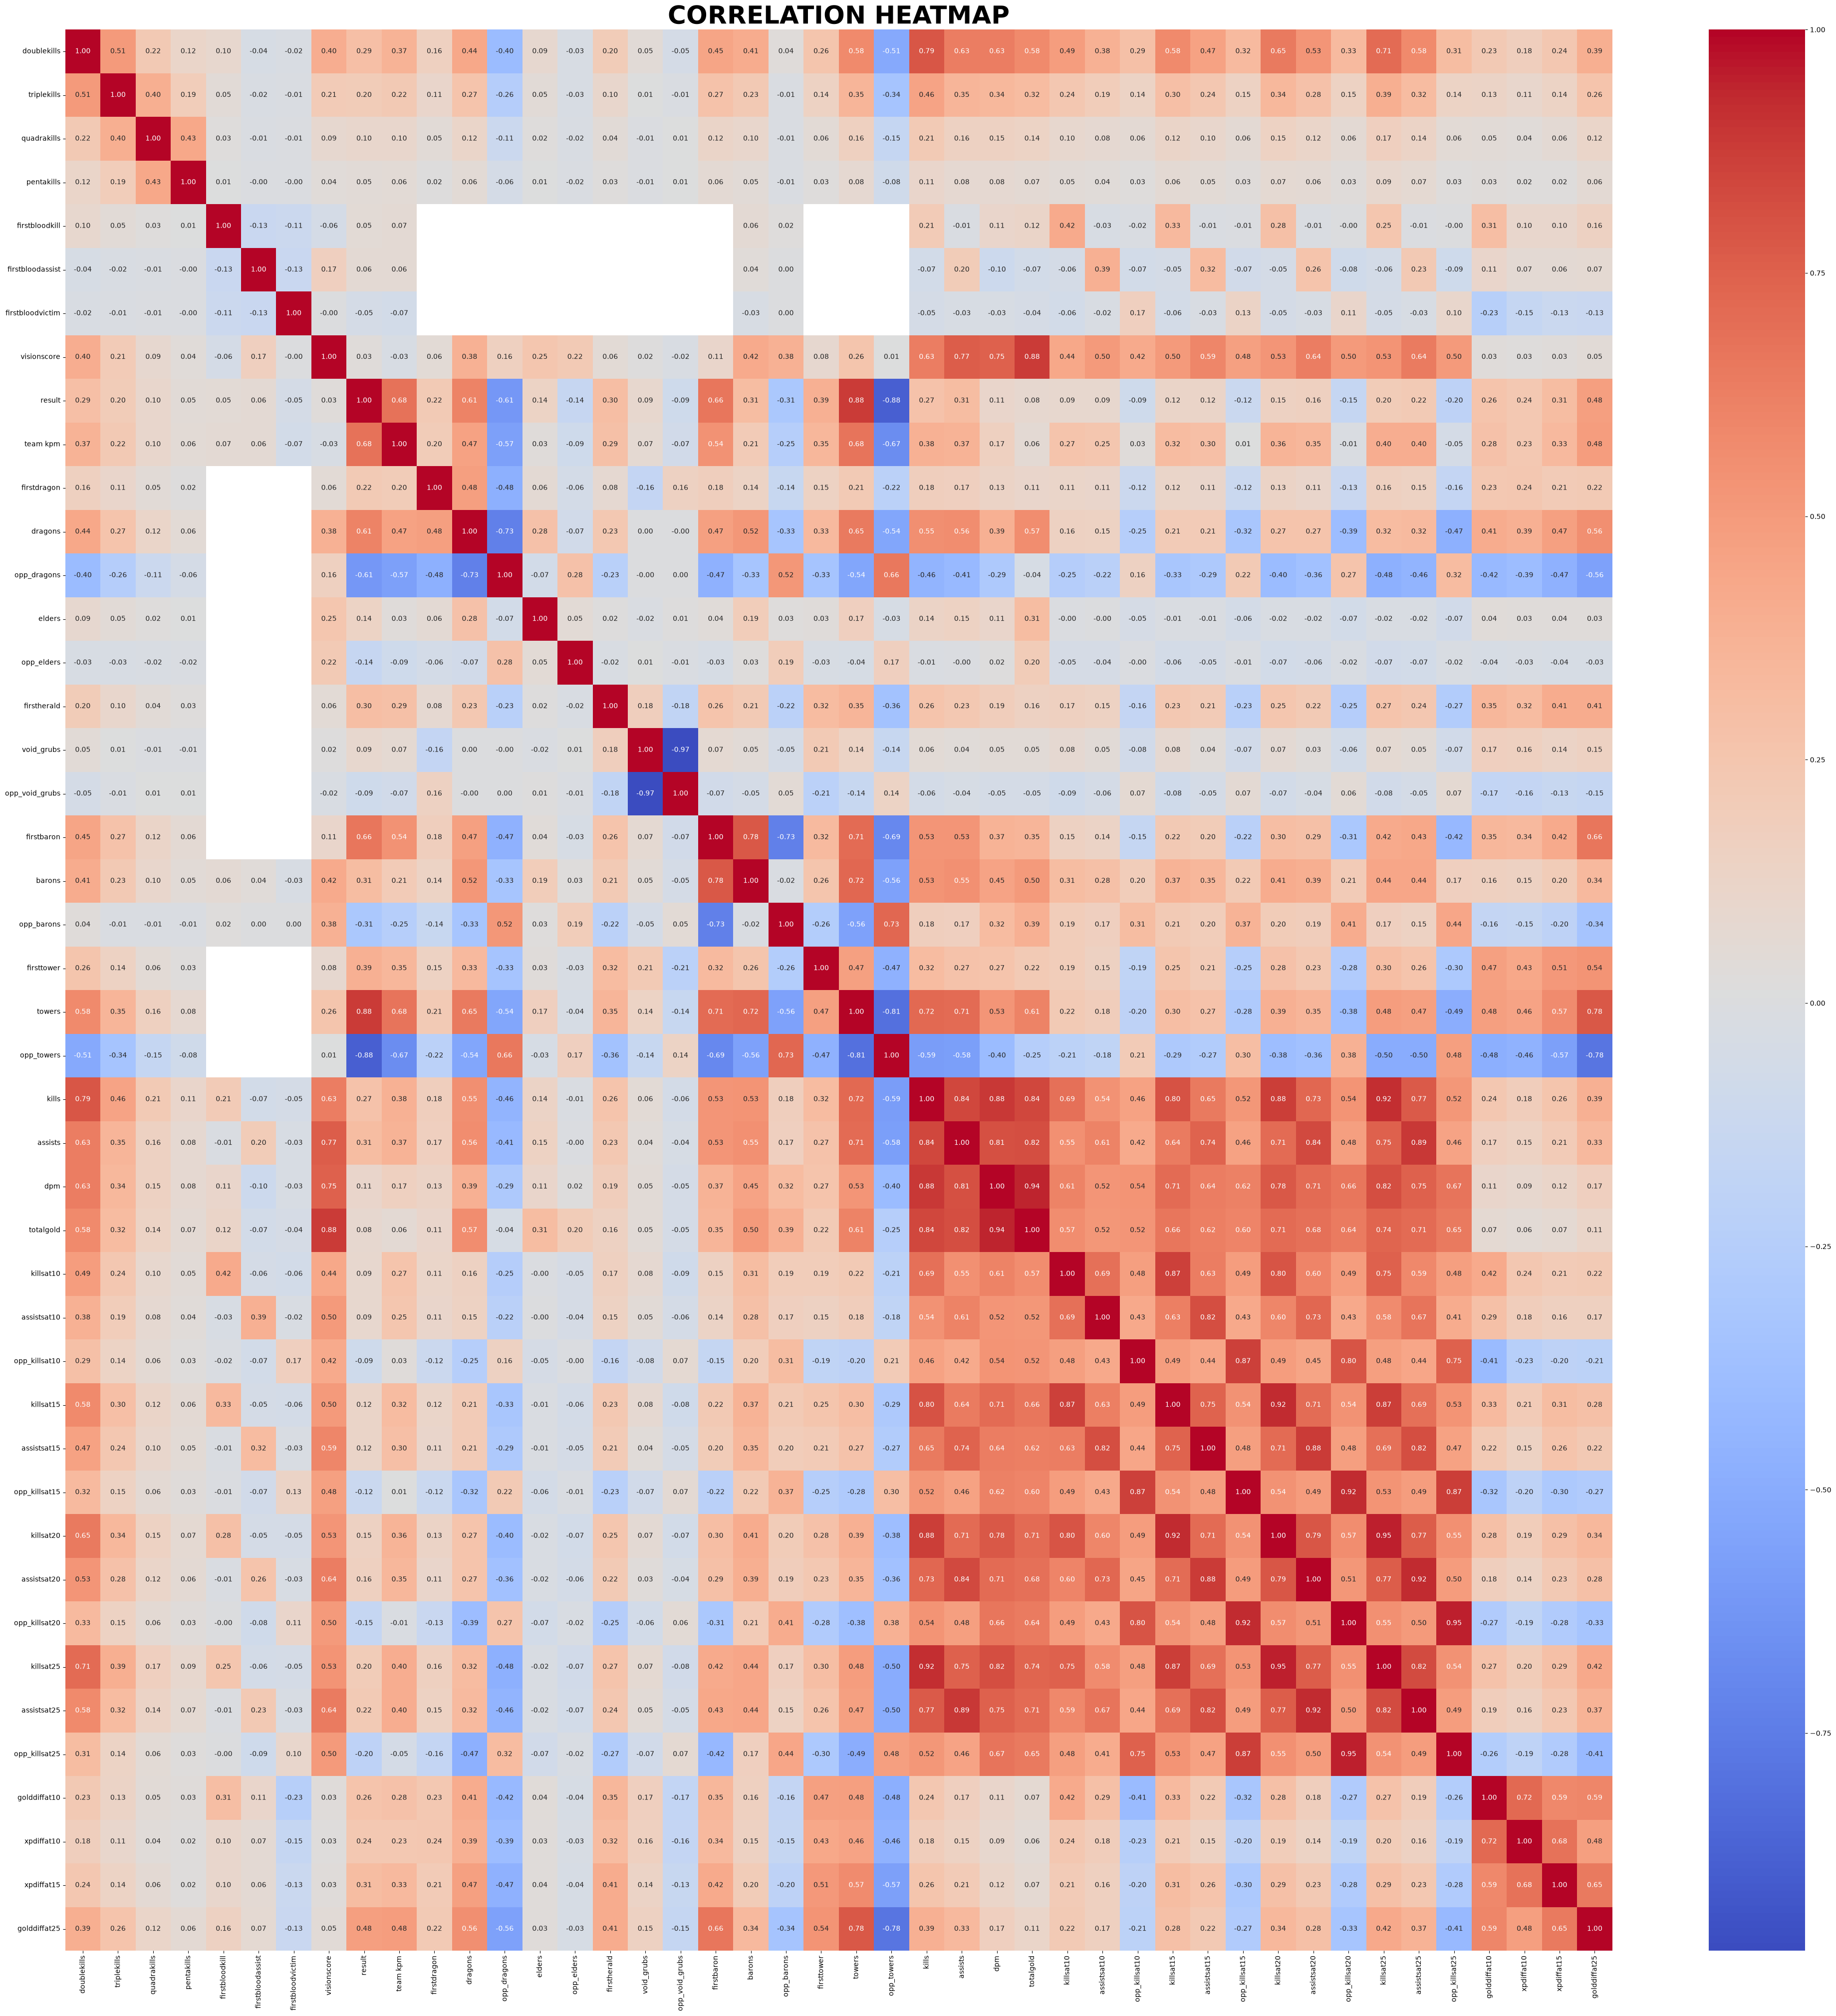

In [16]:
# Compute correlation matrix
corr_mtx = df.corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(50, 50))
sns.heatmap(corr_mtx, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('CORRELATION HEATMAP', fontsize=36, fontweight="bold")
plt.show()

In [17]:
df.to_csv("df_processed.csv", index=False)